<a href="https://colab.research.google.com/github/Subhashree-175/S2S/blob/main/Copy_of_s2s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    raise RuntimeError("Please select T4 GPU in Runtime settings.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
!pip install -q diffusers transformers accelerate safetensors
!pip install -q opencv-python pillow matplotlib

In [ ]:
import diffusers
import transformers
import accelerate
import cv2

print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("OpenCV:", cv2.__version__)

Diffusers: 0.35.2
Transformers: 4.57.6
Accelerate: 1.15.0
OpenCV: 4.14.0


In [ ]:
import torch
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline,
    UniPCMultistepScheduler
)

print("All model classes imported successfully!")

All model classes imported successfully!


In [ ]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)

print("ControlNet loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


ControlNet loaded successfully!


In [ ]:
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.enable_model_cpu_offload()

print("Stable Diffusion + ControlNet ready!")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stable Diffusion + ControlNet ready!


In [ ]:
print("Device:", torch.cuda.get_device_name(0))
print("Pipeline:", type(pipe).__name__)
print("ControlNet:", type(controlnet).__name__)

Device: Tesla T4
Pipeline: StableDiffusionControlNetPipeline
ControlNet: ControlNetModel


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

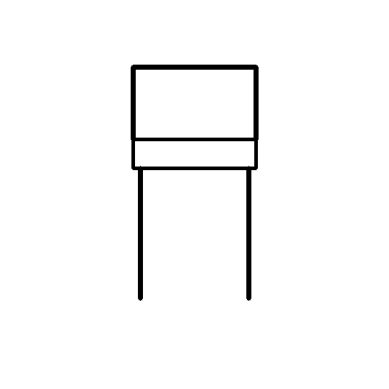

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a white canvas
canvas = np.ones((512, 512, 3), dtype=np.uint8) * 255

# Draw a simple chair
cv2.rectangle(canvas, (170, 180), (340, 220), (0, 0, 0), 4)
cv2.line(canvas, (180, 220), (180, 400), (0, 0, 0), 5)
cv2.line(canvas, (330, 220), (330, 400), (0, 0, 0), 5)
cv2.line(canvas, (170, 180), (170, 80), (0, 0, 0), 5)
cv2.line(canvas, (340, 180), (340, 80), (0, 0, 0), 5)
cv2.line(canvas, (170, 80), (340, 80), (0, 0, 0), 5)

plt.imshow(canvas)
plt.axis("off")

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

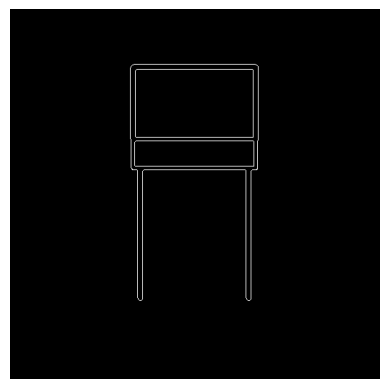

In [ ]:
from PIL import Image

gray = cv2.cvtColor(canvas, cv2.COLOR_RGB2GRAY)

edges = cv2.Canny(gray, 50, 150)

edge_image = Image.fromarray(edges).convert("RGB")

plt.imshow(edge_image)
plt.axis("off")

  0%|          | 0/25 [00:00<?, ?it/s]

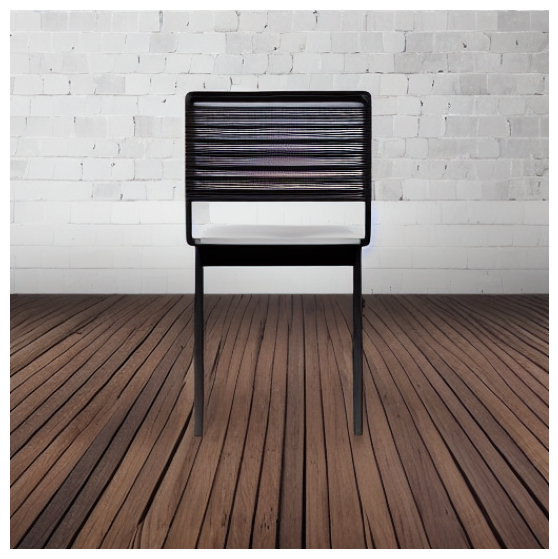

In [ ]:
prompt = """
A beautiful modern wooden chair, realistic product photography,
high quality wooden texture, studio lighting,
detailed craftsmanship, plain white background
"""

negative_prompt = """
blurry, distorted, low quality, extra legs,
deformed structure, unrealistic geometry
"""

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=edge_image,
    num_inference_steps=25,
    controlnet_conditioning_scale=0.8,
    guidance_scale=7.5,
    height=512,
    width=512
).images[0]

plt.figure(figsize=(7, 7))
plt.imshow(result)
plt.axis("off")
plt.show()

In [ ]:
result.save("generated_chair.png")

In [ ]:
!git clone https://github.com/VAST-AI-Research/TripoSR.git

fatal: destination path 'TripoSR' already exists and is not an empty directory.


In [ ]:
%cd /content/TripoSR

/content/TripoSR


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA: True


In [ ]:
!pip install --force-reinstall setuptools==81.0.0

  Using cached setuptools-81.0.0-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-81.0.0-py3-none-any.whl (1.1 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.


In [ ]:
import setuptools
import torch

print("Setuptools:", setuptools.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Setuptools: 81.0.0
PyTorch: 2.11.0+cu130
CUDA: True


In [ ]:
%pip install -U scikit-build-core pybind11 cmake ninja

In [ ]:
!nvcc --version
!cmake --version
!g++ --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
cmake version 4.4.4

CMake suite maintained and supported by Kitware (kitware.com/cmake).
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [ ]:
%pip install --no-build-isolation git+https://github.com/tatsy/torchmcubes.git

  Cloning https://github.com/tatsy/torchmcubes.git to /tmp/pip-req-build-wx5arz1_
  Running command git clone --filter=blob:none --quiet https://github.com/tatsy/torchmcubes.git /tmp/pip-req-build-wx5arz1_
  Resolved https://github.com/tatsy/torchmcubes.git to commit a9ac95aa329957ba646e7bb057f825f5dfa77f38
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import torchmcubes

print("PyTorch:", torch.__version__)
print("TorchMCubes:", torchmcubes.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
TorchMCubes: 0.1.0
CUDA: True


In [ ]:
%cd /content/TripoSR

!cat requirements.txt

/content/TripoSR
omegaconf==2.3.0
Pillow==10.1.0
einops==0.7.0
git+https://github.com/tatsy/torchmcubes.git
transformers==4.35.0
trimesh==4.0.5
rembg
huggingface-hub
imageio[ffmpeg]
gradio
xatlas==0.0.9
moderngl==5.10.0


In [ ]:
%pip install "Pillow>=11,<13"

In [ ]:
%pip install omegaconf==2.3.0 einops==0.7.0 trimesh==4.0.5

  Using cached trimesh-4.0.5-py3-none-any.whl.metadata (18 kB)
Using cached trimesh-4.0.5-py3-none-any.whl (688 kB)
ERROR: Operation cancelled by user
^C


In [ ]:
%pip install rembg huggingface-hub "imageio[ffmpeg]"

In [ ]:
%pip install xatlas==0.0.11

In [ ]:
%pip install moderngl==5.10.0

In [ ]:
import xatlas
import moderngl
import torch

print("XAtlas installed!")
print("ModernGL installed!")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

XAtlas installed!
ModernGL installed!
PyTorch: 2.11.0+cu130
CUDA: True


In [ ]:
%pip install "rembg[cpu]"

In [ ]:
import torch
import torchmcubes
import trimesh
import rembg
import omegaconf
import einops
import xatlas
import moderngl
import onnxruntime
import PIL

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("ONNX Runtime:", onnxruntime.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

All imports successful!
PyTorch: 2.11.0+cu130
ONNX Runtime: 1.31.1
CUDA: True
GPU: Tesla T4


In [ ]:
%cd /content/TripoSR

!ls

/content/TripoSR
examples  generated_chair.png  LICENSE	README.md	  run.py   tsr
figures   gradio_app.py        output	requirements.txt  TripoSR


In [ ]:
!cat config.yaml

cat: config.yaml: No such file or directory


In [ ]:
!python run.py --help

usage: run.py [-h] [--device DEVICE]
              [--pretrained-model-name-or-path PRETRAINED_MODEL_NAME_OR_PATH]
              [--chunk-size CHUNK_SIZE] [--mc-resolution MC_RESOLUTION]
              [--no-remove-bg] [--foreground-ratio FOREGROUND_RATIO]
              [--output-dir OUTPUT_DIR] [--model-save-format {obj,glb}]
              [--bake-texture] [--texture-resolution TEXTURE_RESOLUTION]
              [--render]
              image [image ...]

positional arguments:
  image                 Path to input image(s).

options:
  -h, --help            show this help message and exit
  --device DEVICE       Device to use. If no CUDA-compatible device is found,
                        will fallback to 'cpu'. Default: 'cuda:0'
  --pretrained-model-name-or-path PRETRAINED_MODEL_NAME_OR_PATH
                        Path to the pretrained model. Could be either a
                        huggingface model id is or a local path. Default:
                        'stabilityai/TripoSR'
  --c

In [ ]:
%cd /content/TripoSR
!ls examples/

/content/TripoSR
captured.jpeg  hamburger.png  marble.png	robot.png    tiger_girl.png
chair.png      horse.png      police_woman.png	stripes.png  unicorn.png
flamingo.png   iso_house.png  poly_fox.png	teapot.png


In [ ]:
import torch
import transformers
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Transformers: 4.57.6
Hugging Face Hub: 0.36.0
CUDA: True


In [ ]:
%cd /content/TripoSR

!python run.py examples/chair.png \
    --device cuda:0 \
    --output-dir output/ \
    --model-save-format glb \
    --bake-texture

/content/TripoSR
2026-10-31 18:56:10,537 - INFO - Initializing model ...
2026-10-31 18:56:13,930 - INFO - NumExpr defaulting to 2 threads.
I0000 00:00:1793472975.296932   34175 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793472977.992384   34175 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-31 18:56:31,841 - INFO - Initializing model finished in 21303.61ms.
2026-10-31 18:56:31,841 - INFO - Processing images ...
2026-10-31 18:56:48,484 - INFO - Processing images finished in 16642.28ms.
2026-10-31 18:56:48,484 - INFO - Running image 1/1 ...
2026-10-31 18:56:48,484 - INFO - Running model ...
2026-10-31 18:56:49,802 - INFO - Running model finished in 1318.42ms.
2026-10-31 18:56:49,803 - INFO - Extracting mesh ...

In [ ]:
%cd /content/TripoSR

!python run.py examples/chair.png \
    --device cuda:0 \
    --output-dir output/ \
    --model-save-format glb

/content/TripoSR
2026-10-31 18:57:40,607 - INFO - Initializing model ...
2026-10-31 18:57:43,861 - INFO - NumExpr defaulting to 2 threads.
I0000 00:00:1793473064.820189   34590 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793473067.247247   34590 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-31 18:57:59,269 - INFO - Initializing model finished in 18662.29ms.
2026-10-31 18:57:59,270 - INFO - Processing images ...
2026-10-31 18:58:15,028 - INFO - Processing images finished in 15757.68ms.
2026-10-31 18:58:15,028 - INFO - Running image 1/1 ...
2026-10-31 18:58:15,028 - INFO - Running model ...
2026-10-31 18:58:16,420 - INFO - Running model finished in 1391.72ms.
2026-10-31 18:58:16,420 - INFO - Extracting mesh ...

In [ ]:
%pip install numpy==1.26.4

  Using cached numpy-1.26.4-cp313-cp313-linux_x86_64.whl
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
rembg 2.0.86 requires numpy<3.0.0,>=2.3.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0,

In [ ]:
import numpy
import trimesh
import torch

print("NumPy:", numpy.__version__)
print("Trimesh:", trimesh.__version__)
print("CUDA:", torch.cuda.is_available())

NumPy: 1.26.4
Trimesh: 5.2.0
CUDA: True


In [ ]:
%pip install trimesh==5.2.0

In [ ]:
import numpy
import trimesh
import cupy
import torch

print("NumPy:", numpy.__version__)
print("Trimesh:", trimesh.__version__)
print("CuPy:", cupy.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

ImportError: 
================================================================
Failed to import CuPy.

If you installed CuPy via wheels (cupy-cudaXXX or cupy-rocm-X-X), make sure that the package matches with the version of CUDA or ROCm installed.

On Linux, you may need to set LD_LIBRARY_PATH environment variable depending on how you installed CUDA/ROCm.
On Windows, try setting CUDA_PATH environment variable.

Check the Installation Guide for details:
  https://docs.cupy.dev/en/latest/install.html

Original error:
  ImportError: numpy.core.multiarray failed to import (auto-generated because you didn't call 'numpy.import_array()' after cimporting numpy; use '<void>numpy._import_array' to disable if you are certain you don't need it).
================================================================


In [ ]:
!pip show cupy cupy-cuda13x cupy-cuda12x numpy

Name: cupy-cuda13x
Version: 14.0.1
Summary: CuPy: NumPy & SciPy for GPU
Home-page: https://cupy.dev/
Author: 
Author-email: Seiya Tokui <tokui@preferred.jp>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-pathfinder, numpy
Required-by: cucim-cu13, cudf-cu13, cuml-cu13, dask-cudf-cu13, nvforest-cu13, nx-cugraph-cu13, pylibcugraph-cu13, rapidsmpf-cu13
---
Name: numpy
Version: 1.26.4
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License: Copyright (c) 2005-2023, NumPy Developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are
 met:

     * Redistributions of source code must retain the above copyright
        notice, this list of conditions and the following disclaimer.

     * Redistributions in binary form must reproduce the above
        copy

In [ ]:
%pip install numpy==2.4.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 41.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.


In [ ]:
%cd /content/TripoSR

!python run.py examples/chair.png \
    --device cuda:0 \
    --output-dir output/ \
    --model-save-format glb

/content/TripoSR
2026-10-31 19:01:28,125 - INFO - Initializing model ...
2026-10-31 19:01:34,712 - INFO - NumExpr defaulting to 2 threads.
I0000 00:00:1793473297.219711   35844 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793473305.309974   35844 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-31 19:02:03,300 - INFO - Initializing model finished in 35175.51ms.
2026-10-31 19:02:03,300 - INFO - Processing images ...
2026-10-31 19:02:19,596 - INFO - Processing images finished in 16295.39ms.
2026-10-31 19:02:19,596 - INFO - Running image 1/1 ...
2026-10-31 19:02:19,596 - INFO - Running model ...
2026-10-31 19:02:20,838 - INFO - Running model finished in 1241.79ms.
2026-10-31 19:02:20,838 - INFO - Extracting mesh ...

In [ ]:
!find /content/TripoSR/output -type f

/content/TripoSR/output/0/input.png
/content/TripoSR/output/0/mesh.glb


In [ ]:
from google.colab import files

files.download('/content/TripoSR/output/0/mesh.glb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install diffusers==0.35.2 --no-deps

In [ ]:
import torch
import diffusers
import transformers
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Hub:", huggingface_hub.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Diffusers: 0.35.2
Transformers: 4.57.6
Hub: 0.36.0
CUDA: True


In [ ]:
import torch
import cv2
import numpy as np

from PIL import Image
from diffusers import ControlNetModel
from diffusers import StableDiffusionControlNetPipeline
from diffusers import UniPCMultistepScheduler

print("Imports successful!")

Imports successful!


In [ ]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.enable_model_cpu_offload()

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


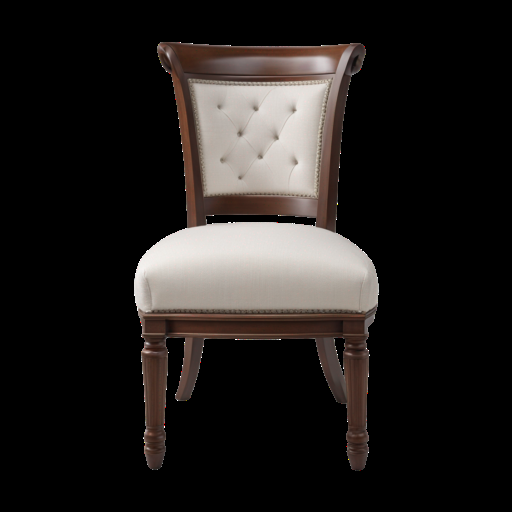

In [ ]:
sketch = Image.open(
    "/content/TripoSR/examples/chair.png"
).convert("RGB")

sketch = sketch.resize((512, 512))

display(sketch)

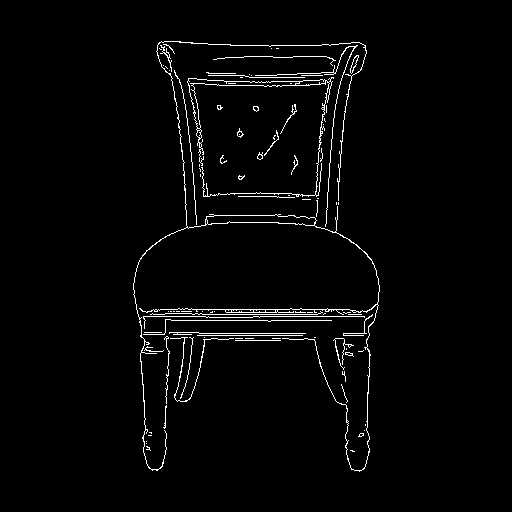

In [ ]:
image_np = np.array(sketch)

edges = cv2.Canny(image_np, 100, 200)

edges = np.stack([edges] * 3, axis=-1)

edge_image = Image.fromarray(edges)

display(edge_image)

  0%|          | 0/25 [00:00<?, ?it/s]

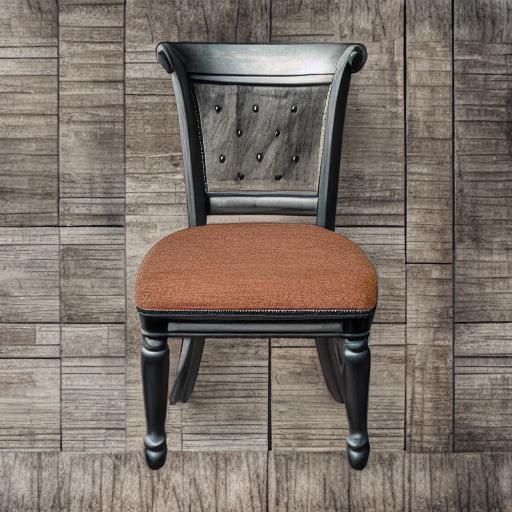

In [ ]:
result = pipe(
    prompt="A realistic wooden chair, studio photography, "
           "detailed wood texture, professional product photography",
    image=edge_image,
    num_inference_steps=25,
    guidance_scale=7.5,
    controlnet_conditioning_scale=0.8
)

generated_image = result.images[0]

display(generated_image)

generated_image.save("/content/generated_chair.png")

In [ ]:
import torch
import cv2
import numpy as np

from PIL import Image
from diffusers import ControlNetModel
from diffusers import StableDiffusionControlNetPipeline
from diffusers import UniPCMultistepScheduler

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

All imports successful!
PyTorch: 2.11.0+cu130
CUDA available: True


In [ ]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)

print("ControlNet loaded successfully!")

ControlNet loaded successfully!


In [ ]:
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.enable_model_cpu_offload()

print("Stable Diffusion + ControlNet loaded successfully!")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stable Diffusion + ControlNet loaded successfully!


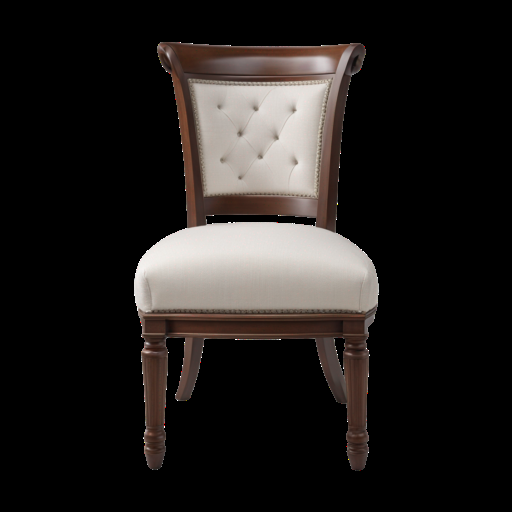

In [ ]:
sketch = Image.open(
    "/content/TripoSR/examples/chair.png"
).convert("RGB")

sketch = sketch.resize((512, 512))

display(sketch)

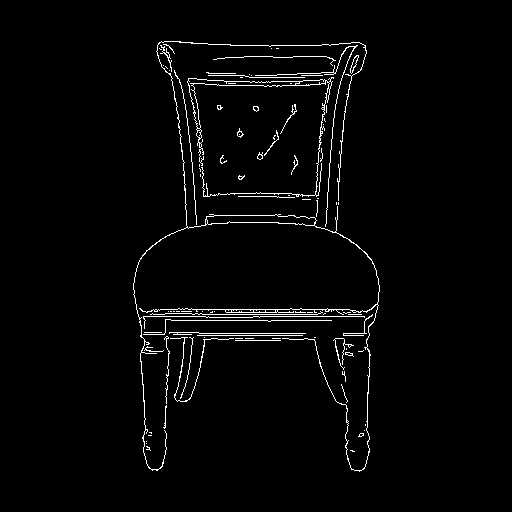

In [ ]:
image_np = np.array(sketch)

edges = cv2.Canny(image_np, 100, 200)

edges = np.stack([edges] * 3, axis=-1)

edge_image = Image.fromarray(edges)

display(edge_image)

  0%|          | 0/25 [00:00<?, ?it/s]

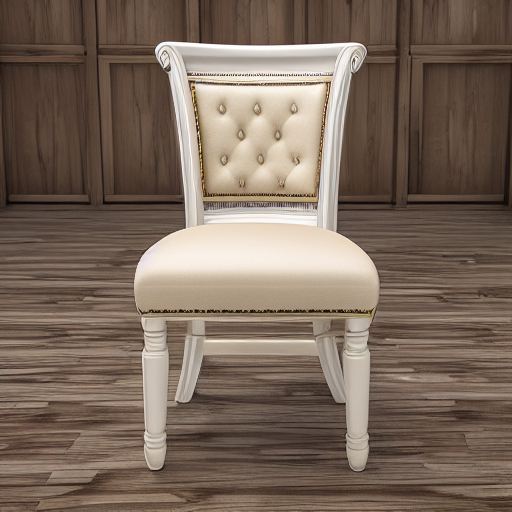

Chair image generated successfully!


In [ ]:
result = pipe(
    prompt=(
        "A photorealistic elegant wooden dining chair, "
        "cream upholstered seat and backrest, "
        "detailed wooden frame, studio product photography, "
        "high quality, realistic lighting, white background"
    ),
    negative_prompt="blurry, distorted, extra legs, deformed furniture",
    image=edge_image,
    num_inference_steps=25,
    guidance_scale=7.5,
    controlnet_conditioning_scale=0.8,
    height=512,
    width=512
)

generated_image = result.images[0]

display(generated_image)

generated_image.save("/content/generated_chair.png")

print("Chair image generated successfully!")

In [ ]:
%cd /content/TripoSR

!python run.py /content/generated_chair.png \
    --device cuda:0 \
    --output-dir /content/Sketch2Shape_Output \
    --model-save-format glb

/content/TripoSR
2026-10-31 19:15:31,776 - INFO - Initializing model ...
2026-10-31 19:15:35,738 - INFO - NumExpr defaulting to 2 threads.
I0000 00:00:1793474139.251330   39614 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793474143.836192   39614 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-31 19:15:58,381 - INFO - Initializing model finished in 26605.04ms.
2026-10-31 19:15:58,381 - INFO - Processing images ...
2026-10-31 19:17:17,691 - INFO - Processing images finished in 79310.19ms.
2026-10-31 19:17:17,692 - INFO - Running image 1/1 ...
2026-10-31 19:17:17,692 - INFO - Running model ...
2026-10-31 19:17:20,381 - INFO - Running model finished in 2689.32ms.
2026-10-31 19:17:20,381 - INFO - Extracting mesh ...

In [ ]:
!find /content/Sketch2Shape_Output -type f

/content/Sketch2Shape_Output/0/input.png
/content/Sketch2Shape_Output/0/mesh.glb


In [ ]:
from google.colab import files

files.download(
    "/content/Sketch2Shape_Output/0/mesh.glb"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>